Load the Graph

In [13]:
import pandas as pd

SNAP_URL = "https://snap.stanford.edu/data/soc-sign-bitcoinotc.csv.gz"

df = pd.read_csv(
    SNAP_URL,
    compression="gzip",
    header=None,
    names=["source", "target", "sign", "timestamp"]
)

print(df.head())
print(df.shape)

   source  target  sign     timestamp
0       6       2     4  1.289242e+09
1       6       5     2  1.289242e+09
2       1      15     1  1.289243e+09
3       4       3     7  1.289245e+09
4      13      16     8  1.289254e+09
(35592, 4)


In [14]:
import numpy as np

random_df = df.copy()

def random_signed_weight(original_sign):
    if original_sign > 0:
        # Random positive weight between 0 and 1
        return np.random.uniform(0.0, 1.0)

    elif original_sign < 0:
        # Random negative weight between -1 and 0
        return np.random.uniform(-1.0, 0.0)

    else:
        # Keep zero as zero
        return 0.0

# Apply function to update the 'sign' column
random_df["sign"] = random_df["sign"].apply(random_signed_weight)

# Print a random sample of 5 values to inspect the output
print("Random sample of generated weights:")
print(random_df["sign"].sample(min(5, len(random_df)), random_state=42))

Random sample of generated weights:
5777     0.348347
10509    0.621520
13144    0.091938
31893    0.029612
7680     0.889742
Name: sign, dtype: float64


Graph Representation

In [15]:
#converting dataframe into dictionary graph
graph = {}

# changed this df to random_df
for _, row in random_df.iterrows(): #iterrows() give index and row we dont care about index so we used _
    u = int(row["source"])
    v = int(row["target"])
    signed_edge_weight = row["sign"]

    if u not in graph:
        graph[u] = []

    graph[u].append((v, signed_edge_weight))


for node, edges in list(graph.items())[:5]:
  print(node, edges) #graph[node] = [(neighbor, weight), ...]

6 [(2, 0.3269800258883728), (5, 0.7402655083727799), (4, 0.005085378210815117), (7, 0.0057398709396637715), (114, 0.7728345669989856), (32, 0.034562173218831704), (173, 0.4832278423756182), (258, 0.4794437359978254), (268, 0.09331634051163584), (219, 0.5618657460335114), (198, 0.9472994977859786), (35, 0.29747690581628683), (664, 0.40864664616083324), (937, 0.5354011758656575), (384, 0.7076400009079044), (521, 0.6733892757384197), (280, 0.5393432625336265), (687, 0.3157573421970098), (1386, 0.8808581375121602), (537, 0.9470228505855671), (1317, 0.4646360623866902), (1566, 0.6271454402486123), (2034, 0.35315061500952727), (2455, 0.03406353700318132), (1383, -0.42414872202084886), (1810, 0.9606314195072251), (2028, 0.6518073245230884), (1363, 0.429148016868648), (10, 0.5984039834092472), (1, 0.37830941567159126), (1018, 0.45566862752645165), (1832, 0.4704021144197694), (1624, 0.7763707945421213), (550, 0.25123914545084625), (1331, -0.49569663227363026), (2642, 0.5736187504063742), (856, 

Finding Highest Degree Node

In [16]:
#calculate degree
degree = {}

for node, edges in graph.items():
    degree[node] = len(edges)

D = 5 #top k degree we want

top_k_nodes = sorted(
    degree,
    key=degree.get,
    reverse=True
)[:D]

for node in top_k_nodes:
    print(node, degree[node])  #node and it's total degree

35 763
2642 406
1810 404
2125 397
2028 293


Making Domains

In [17]:
import numpy as np

nodes = set(random_df["source"].astype(int)) | set(random_df["target"].astype(int)) #nodes that can appear only as a target (v).

nodes = list(nodes)

Domain_we_want = 5 #domains we want

np.random.shuffle(nodes)

domains = {}

for i, node in enumerate(nodes): #loop over iterable keeping track of index too and also value which is node
    domains[node] = i % Domain_we_want

print(list(domains.items())[:10])

for instance in range(Domain_we_want): #how many node each instance has
    count = sum(1 for d in domains.values() if d == instance)
    print("Instance", instance, ":", count, "nodes")

[(5049, 0), (344, 1), (556, 2), (5192, 3), (5893, 4), (4292, 0), (2137, 1), (1211, 2), (1037, 3), (1959, 4)]
Instance 0 : 1177 nodes
Instance 1 : 1176 nodes
Instance 2 : 1176 nodes
Instance 3 : 1176 nodes
Instance 4 : 1176 nodes


Fediverse Matrix

In [18]:
F = np.random.uniform(0, 1, size=(Domain_we_want, Domain_we_want))

# Same-instance relationship
np.fill_diagonal(F, 1.0)

print(F)

[[1.         0.65039748 0.4181759  0.65005731 0.67495026]
 [0.18631243 1.         0.29727063 0.87960486 0.43027738]
 [0.54665556 0.03831688 1.         0.24125242 0.13577268]
 [0.62219863 0.3009053  0.06106174 1.         0.74991391]
 [0.21391983 0.85102886 0.0093639  0.30843522 1.        ]]


Diffusion Model

In [19]:
def diffusion_model(
    graph,
    seeds,
    domains,
    threshold_for_cross_domain,
    F,
    iterations,
    learning_rate,
    user_threshold
):

    # Initial state
    positive_active = set(seeds)
    negative_active = set()

    # Initially, only seeds are allowed to propagate
    current_positive = set(seeds)
    current_negative = set()

    for iteration in range(iterations):


        # 1. Same-domain diffusion
        positive_active, negative_active, same_new_positive, same_new_negative = (
            same_domain_diffusion(
                graph,
                positive_active,
                negative_active,
                domains,
                current_positive,
                current_negative
            )
        )

        # 2. Cross-domain diffusion
        positive_active, negative_active, domain_influence, cross_new_positive, cross_new_negative = (
            cross_domain_diffusion(
                graph,
                positive_active,
                negative_active,
                domains,
                threshold_for_cross_domain,
                F,
                current_positive,
                current_negative,
                user_threshold
            )
        )



        # 3. Update federation
        F = update_federation(
            F,
            domain_influence,
            learning_rate
        )

        # Combine newly activated nodes from both diffusion mechanisms
    # current_positive = same_new_positive | cross_new_positive
    # current_negative = same_new_negative | cross_new_negative
    # Full re-evaluation: every active node propagates next round
    current_positive = positive_active
    current_negative = negative_active

    return positive_active, negative_active

Same Domain Diffusion

In [20]:
#We shouldn't immediately put a node into new_positive or new_negative when an edge succeeds, because the same node may receive influence from several active nodes during the same round.

def same_domain_diffusion(graph, positive_active, negative_active,
                          domains, current_positive, current_negative):
    """
    Strict signed IC within the same domain.

    Rules:
      - Probability of transmission along edge (u, v) is |signed_edge_weight|.
      - The message carried is source_polarity * signed_edge_weight.
        * source_polarity = +1 if u is in current_positive
        * source_polarity = -1 if u is in current_negative
      - The FIRST successful edge into v decides v's state.
      - Once v is active (either polarity), it is never reconsidered (Rule A).
    """

    new_positive = set()
    new_negative = set()

    current_active = current_positive | current_negative

    for u in current_active:

        source_polarity = 1 if u in current_positive else -1

        for v, signed_edge_weight in graph.get(u, []):

            # Same-domain only
            if domains[u] != domains[v]:
                continue

            # Rule A: once active (in any polarity), v is frozen.
            if v in positive_active or v in negative_active:
                continue

            # Already decided this round → first success wins
            if v in new_positive or v in new_negative:
                continue

            # Skip zero-weight edges — they can't transmit influence
            if signed_edge_weight == 0:
                continue


            # IC attempt: probability = |edge weight|
            if np.random.random() < abs(signed_edge_weight):

                effective = source_polarity * signed_edge_weight

                if effective > 0:
                    new_positive.add(v)
                elif effective < 0:
                    new_negative.add(v)
                # effective == 0 → no activation ()

    # Keep the global active sets disjoint
    positive_active.update(new_positive)
    negative_active.difference_update(new_positive)

    negative_active.update(new_negative)
    positive_active.difference_update(new_negative)

    return positive_active, negative_active, new_positive, new_negative

Cross Domain Diffusion

In [21]:
def cross_domain_diffusion(
    graph,
    positive_active,
    negative_active,
    domains,
    threshold_for_cross_domain,
    F,
    current_positive,
    current_negative,
    user_threshold
):
    """
    Signed LT across domains WITH polarity switching.

    - Re-evaluates every currently active node each round.
    - A node's state can flip if the net cross-domain influence
      this round crosses its threshold in the opposite direction.
    - A node's state is unchanged if |net| < threshold.
    - domain_influence records only edges that led to a state change,
      so update_federation learns from realised influence.
    """

    influence = {}          # v -> list of signed influence values
    edge_source = {}        # v -> list of (source_domain, target_domain)

    # We scan from current_positive | current_negative (the propagators).
    # But we accept targets that are already active too — that's how switching happens.
    current_active = current_positive | current_negative

    for u in sorted(current_active):

        source_domain = domains[u]
        source_polarity = 1 if u in current_positive else -1

        for v, signed_edge_weight in graph.get(u, []):

            # Skip zero-weight edges
            if signed_edge_weight == 0:
                continue

            # Only cross-domain edges
            target_domain = domains[v]
            if source_domain == target_domain:
                continue

            # NOTE: no "already active → skip" guard here.
            # We WANT to influence active nodes so they can flip.

            federation_weight = F[source_domain][target_domain]

            influence_value = (
                source_polarity
                * signed_edge_weight
                * federation_weight
            )

            if v not in influence:
                influence[v] = []
                edge_source[v] = []

            influence[v].append(influence_value)
            edge_source[v].append((source_domain, target_domain))

    new_positive = set()
    new_negative = set()
    domain_influence = {}

    for v, influences in influence.items():

        # Signed LT: net influence
        net = sum(influences)

        effective_threshold = max(
            threshold_for_cross_domain,
            user_threshold[v]
        )

        # Threshold not reached → no state change
        if abs(net) < effective_threshold:
            continue

        # Determine the proposed new state
        proposed_positive = net > 0
        proposed_negative = net < 0

        # Current state of v
        was_positive = v in positive_active
        was_negative = v in negative_active

        # If v is already in the proposed state, nothing changes
        if proposed_positive and was_positive:
            continue
        if proposed_negative and was_negative:
            continue

        # Otherwise, v changes state (new activation OR flip)
        if proposed_positive:
            positive_active.add(v)
            negative_active.discard(v)
            new_positive.add(v)      # register the delta for next round
        else:
            negative_active.add(v)
            positive_active.discard(v)
            new_negative.add(v)

        # Record domain influence ONLY for edges that contributed
        # to an actual state change
        for (sd, td) in edge_source[v]:
            domain_influence.setdefault((sd, td), []).append(net)

    return (
        positive_active,
        negative_active,
        domain_influence,
        new_positive,
        new_negative
    )

Update Fedration Matrix

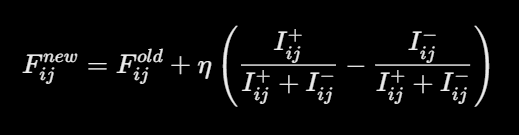

In [22]:
import numpy as np

def update_federation(F, domain_influence, learning_rate=0.1):

    for (source_domain, target_domain), influences in domain_influence.items(): #going through every domain pair

        '''
        source_domain = 0
        target_domain = 1

        influences = [0.4, 0.2, -0.1, 0.5]
        '''

        positive_influence = sum(
            x for x in influences if x > 0
        )

        negative_influence = sum(
            abs(x) for x in influences if x < 0
        )

        total_influence = positive_influence + negative_influence

        # No influence between these domains
        if total_influence == 0:
            continue

        # Fractions
        positive_fraction = positive_influence / total_influence
        negative_fraction = negative_influence / total_influence

        # Positive → increase F
        # Negative → decrease F
        net_fraction = positive_fraction - negative_fraction

        F[source_domain][target_domain] += (
            learning_rate * net_fraction
        )

        # Keep federation score between 0 and 1
        F[source_domain][target_domain] = np.clip(
            F[source_domain][target_domain],
            0,
            1
        )

    return F

creating user threshold for cross domain

In [23]:
user_threshold = {
    node: np.random.uniform(0, 1)
    for node in domains
}

Calling Diffuison main

In [24]:
threshold_for_cross_domain = 0.3

positive, negative = diffusion_model(
    graph,
    top_k_nodes,
    domains,
    threshold_for_cross_domain,
    F,
    10,
    0.1,
    user_threshold

)

 #  iterations=10,
 # learning_rate=0.1,

total = len(positive | negative)

print("Positive nodes:", len(positive))
print("Negative nodes:", len(negative))
print("Total influenced nodes:", total)

print("Positive edges:", (random_df["sign"] > 0).sum())
print("Negative edges:", (random_df["sign"] < 0).sum())

print("Positive edge percentage:",
      (random_df["sign"] > 0).mean() * 100)

print("Negative edge percentage:",
      (random_df["sign"] < 0).mean() * 100)

print("Average positive weight:",
      random_df.loc[random_df["sign"] > 0, "sign"].mean() / 10)

print("Average negative magnitude:",
      abs(random_df.loc[random_df["sign"] < 0, "sign"].mean() / 10))

print("Max positive weight:",
      random_df.loc[random_df["sign"] > 0, "sign"].max() / 10)

print("Max negative magnitude:",
      abs(random_df.loc[random_df["sign"] < 0, "sign"].min() / 10))

Positive nodes: 764
Negative nodes: 181
Total influenced nodes: 945
Positive edges: 32029
Negative edges: 3563
Positive edge percentage: 89.98932344347045
Negative edge percentage: 10.010676556529557
Average positive weight: 0.05008141795316327
Average negative magnitude: 0.04959099648416416
Max positive weight: 0.09999670320423681
Max negative magnitude: 0.09999379988044653
